In [1]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# Reproducibility ke liye seed set karna
np.random.seed(42)
random.seed(42)

# 1. Aapke Original Customers + 192 Naye Realistic Customers (Total 200)
original_customers = [
    (101, 'Aarav Sharma', 'Pune', '2025-01-15'),
    (102, 'Priya Patel', 'Mumbai', '2025-02-10'),
    (103, 'Rohan Verma', 'Bengaluru', '2025-03-05'),
    (104, 'Sneha Joshi', 'Pune', '2025-04-20'),
    (105, 'Vikram Singh', 'Delhi', '2025-05-12'),
    (106, 'Ananya Nair', 'Mumbai', '2025-06-18'),
    (107, 'Karan Deshmukh', 'Pune', '2025-07-22'),
    (108, 'Meera Iyer', 'Bengaluru', '2025-08-30')
]

first_names = ['Aditya', 'Neha', 'Rahul', 'Kavita', 'Siddharth', 'Pooja', 'Arjun', 'Divya', 'Manish', 'Snehal']
last_names = ['Kulkarni', 'Mehta', 'Reddy', 'Gupta', 'Chavan', 'Malhotra', 'Bhat', 'Verma', 'Jain', 'Desai']
cities = ['Pune', 'Mumbai', 'Bengaluru', 'Delhi']
city_weights = [0.35, 0.30, 0.20, 0.15]  # Pune & Mumbai top markets (aapke SQL insight ke mutabik)

customers_data = list(original_customers)
start_join = datetime(2025, 1, 1)

for cid in range(109, 301):
    name = f"{random.choice(first_names)} {random.choice(last_names)}"
    city = np.random.choice(cities, p=city_weights)
    join_date = (start_join + timedelta(days=random.randint(0, 300))).strftime('%Y-%m-%d')
    customers_data.append((cid, name, city, join_date))

df_customers = pd.DataFrame(customers_data, columns=['Customer_ID', 'Customer_Name', 'City', 'Join_Date'])

# 2. Aapke Original Sales + 2,000 Naye Orders (Same SQL Business Logic ke sath)
original_sales = [
    (1, 101, '2026-01-10', 'Software', 15000.00, 'Completed'),
    (2, 102, '2026-01-15', 'Consulting', 25000.00, 'Completed'),
    (3, 103, '2026-02-05', 'Hardware', 45000.00, 'Cancelled'),
    (4, 101, '2026-02-20', 'Software', 18000.00, 'Completed'),
    (5, 104, '2026-03-12', 'Support', 8000.00, 'Completed'),
    (6, 105, '2026-04-18', 'Hardware', 50000.00, 'Completed'),
    (7, 106, '2026-05-25', 'Software', 12000.00, 'Cancelled'),
    (8, 102, '2026-06-10', 'Consulting', 30000.00, 'Completed'),
    (9, 107, '2026-07-14', 'Support', 9500.00, 'Completed'),
    (10, 108, '2026-08-19', 'Software', 22000.00, 'Completed'),
    (11, 101, '2026-09-05', 'Consulting', 20000.00, 'Completed'),
    (12, 104, '2026-10-11', 'Hardware', 35000.00, 'Cancelled')
]

sales_data = list(original_sales)
categories = ['Software', 'Consulting', 'Hardware', 'Support']
price_ranges = {
    'Software': (12000, 28000),
    'Consulting': (20000, 45000),
    'Hardware': (30000, 65000),
    'Support': (6000, 15000)
}

for oid in range(13, 2013):
    cust = df_customers.sample(1).iloc[0]
    cid = int(cust['Customer_ID'])
    join_dt = datetime.strptime(cust['Join_Date'], '%Y-%m-%d')
    
    # Order date hamesha Join_Date ke baad aur Nov 2026 se pehle hogi
    min_order_dt = max(join_dt + timedelta(days=5), datetime(2026, 1, 1))
    max_order_dt = datetime(2026, 11, 20)
    days_diff = max(1, (max_order_dt - min_order_dt).days)
    order_dt = (min_order_dt + timedelta(days=random.randint(0, days_diff))).strftime('%Y-%m-%d')
    
    cat = np.random.choice(categories, p=[0.35, 0.25, 0.20, 0.20])
    rev = round(random.uniform(*price_ranges[cat]), -2)
    
    # Realistic Cancellation Logic: Hardware aur high-value orders mein zyada cancellation
    cancel_prob = 0.62 if cat == 'Hardware' else (0.18 if rev > 35000 else 0.10)
    status = 'Cancelled' if random.random() < cancel_prob else 'Completed'
    
    sales_data.append((oid, cid, order_dt, cat, rev, status))

df_sales = pd.DataFrame(sales_data, columns=['Order_ID', 'Customer_ID', 'Order_Date', 'Category', 'Revenue', 'Order_Status'])

# CSV mein save karna (taaki Power BI / Excel mein bhi use ho sake)
df_customers.to_csv('Customers.csv', index=False)
df_sales.to_csv('Sales.csv', index=False)

print("✅ Data Pipeline Ready!")
print(f"Total Customers: {len(df_customers)} | Total Orders: {len(df_sales)}")
print("\n--- Top 5 Merged Records ---")
df_merged = pd.merge(df_sales, df_customers, on='Customer_ID', how='inner')
print(df_merged.head())

✅ Data Pipeline Ready!
Total Customers: 200 | Total Orders: 2012

--- Top 5 Merged Records ---
   Order_ID  Customer_ID  Order_Date    Category  Revenue Order_Status  \
0         1          101  2026-01-10    Software  15000.0    Completed   
1         2          102  2026-01-15  Consulting  25000.0    Completed   
2         3          103  2026-02-05    Hardware  45000.0    Cancelled   
3         4          101  2026-02-20    Software  18000.0    Completed   
4         5          104  2026-03-12     Support   8000.0    Completed   

  Customer_Name       City   Join_Date  
0  Aarav Sharma       Pune  2025-01-15  
1   Priya Patel     Mumbai  2025-02-10  
2   Rohan Verma  Bengaluru  2025-03-05  
3  Aarav Sharma       Pune  2025-01-15  
4   Sneha Joshi       Pune  2025-04-20  


✅ Feature Engineering Complete!

--- Top 5 High-Value Customers ---
     Customer_ID       Customer_Name    City  Total_Orders  Completed_Revenue  \
151          252        Aditya Mehta    Pune            21           445000.0   
51           152  Siddharth Malhotra   Delhi            21           409100.0   
28           129        Arjun Chavan  Mumbai            17           406900.0   
150          251          Arjun Jain  Mumbai            19           382800.0   
54           155        Manish Reddy    Pune            15           365400.0   

     Cancelled_Orders Last_Order_Date  Recency_Days  Cancellation_Rate  
151                 1      2026-10-26            25                4.8  
51                  4      2026-11-20             0               19.0  
28                  2      2026-11-06            14               11.8  
150                 4      2026-10-06            45               21.1  
54                  2      2026-11-03            17               13.3  


C:\Users\rajeg\AppData\Local\Temp\ipykernel_14824\1875443229.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_cancel.index, y=cat_cancel.values, ax=axes[1], palette='Reds_r')


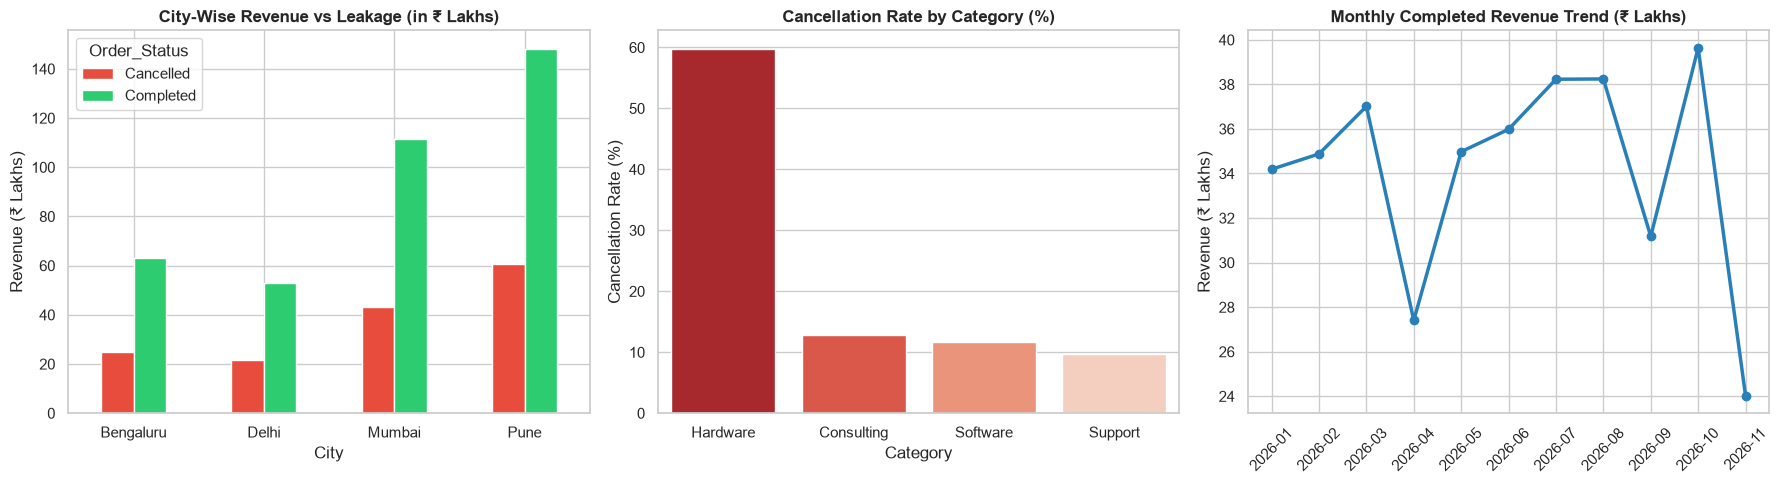

📊 Chart saved as 'business_insights.png'!


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Cleaning & Feature Engineering (Naye kaam ke columns banana)
df_merged['Order_Date'] = pd.to_datetime(df_merged['Order_Date'])
df_merged['Join_Date'] = pd.to_datetime(df_merged['Join_Date'])

# Naya Feature 1: Customer Tenure (Grahak kitne din purana hai order ke waqt)
df_merged['Customer_Tenure_Days'] = (df_merged['Order_Date'] - df_merged['Join_Date']).dt.days

# Naya Feature 2: Order Month & Day of Week
df_merged['Order_Month'] = df_merged['Order_Date'].dt.to_period('M').astype(str)
df_merged['Is_Cancelled'] = df_merged['Order_Status'].apply(lambda x: 1 if x == 'Cancelled' else 0)

# Customer-level Summary (RFM + Churn Risk Metrics)
latest_date = df_merged['Order_Date'].max()
customer_summary = df_merged.groupby(['Customer_ID', 'Customer_Name', 'City']).agg(
    Total_Orders=('Order_ID', 'count'),
    Completed_Revenue=('Revenue', lambda x: x[df_merged.loc[x.index, 'Order_Status'] == 'Completed'].sum()),
    Cancelled_Orders=('Is_Cancelled', 'sum'),
    Last_Order_Date=('Order_Date', 'max')
).reset_index()

customer_summary['Recency_Days'] = (latest_date - customer_summary['Last_Order_Date']).dt.days
customer_summary['Cancellation_Rate'] = round((customer_summary['Cancelled_Orders'] / customer_summary['Total_Orders']) * 100, 1)

print("✅ Feature Engineering Complete!")
print("\n--- Top 5 High-Value Customers ---")
print(customer_summary.sort_values(by='Completed_Revenue', ascending=False).head())

# 2. Executive Business Charts Banana (GitHub ke liye save honge)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: City-wise Completed Revenue vs Cancelled Loss
city_rev = df_merged.groupby(['City', 'Order_Status'])['Revenue'].sum().unstack().fillna(0) / 100000 # Lakhs mein
city_rev.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'])
axes[0].set_title('City-Wise Revenue vs Leakage (in ₹ Lakhs)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Lakhs)')
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: Category Cancellation Rate (%)
cat_cancel = df_merged.groupby('Category')['Is_Cancelled'].mean().sort_values(ascending=False) * 100
sns.barplot(x=cat_cancel.index, y=cat_cancel.values, ax=axes[1], palette='Reds_r')
axes[1].set_title('Cancellation Rate by Category (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Cancellation Rate (%)')

# Chart 3: Monthly Completed Revenue Trend
monthly_rev = df_merged[df_merged['Order_Status'] == 'Completed'].groupby('Order_Month')['Revenue'].sum() / 100000
axes[2].plot(monthly_rev.index, monthly_rev.values, marker='o', color='#2980b9', linewidth=2.5)
axes[2].set_title('Monthly Completed Revenue Trend (₹ Lakhs)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Revenue (₹ Lakhs)')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('business_insights.png', dpi=300)
plt.show()
print("📊 Chart saved as 'business_insights.png'!")

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

# ==========================================
# PART 3: AI / MACHINE LEARNING PREDICTION
# ==========================================

# 1. Machine Learning ke liye Data Taiyar Karna
ml_df = df_merged[['City', 'Category', 'Revenue', 'Customer_Tenure_Days', 'Is_Cancelled']].copy()

# Text columns (City, Category) ko Numbers mein badalna (Encoding)
le_city = LabelEncoder()
le_cat = LabelEncoder()
ml_df['City_Code'] = le_city.fit_transform(ml_df['City'])
ml_df['Category_Code'] = le_cat.fit_transform(ml_df['Category'])

X = ml_df[['City_Code', 'Category_Code', 'Revenue', 'Customer_Tenure_Days']]
y = ml_df['Is_Cancelled']

# Data ko Training (80%) aur Testing (20%) mein baantna
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Random Forest AI Model Train Karna
ai_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
ai_model.fit(X_train, y_train)

# 3. Model ki Accuracy Check Karna
y_pred = ai_model.predict(X_test)
accuracy = round(accuracy_score(y_test, y_pred) * 100, 2)

print(f"🤖 AI Cancellation Prediction Model Trained! Accuracy: {accuracy}%\n")

# 4. Live Prediction: Ek Naye Order ka Risk Check Karna
# Example: Bengaluru se ₹55,000 ka Hardware order, naye customer (Tenure = 15 days) dwara
sample_order = pd.DataFrame({
    'City_Code': [le_city.transform(['Bengaluru'])[0]],
    'Category_Code': [le_cat.transform(['Hardware'])[0]],
    'Revenue': [55000.0],
    'Customer_Tenure_Days': [15]
})

risk_prob = round(ai_model.predict_proba(sample_order)[0][1] * 100, 1)

# ==========================================
# PART 4: AUTOMATED AI BUSINESS ADVISOR
# ==========================================

# Sabhi orders par AI Risk Score lagana
df_merged['AI_Cancel_Risk_%'] = np.round(ai_model.predict_proba(X)[:, 1] * 100, 1)

# High-Risk Completed/Active customers ki list nikalna (Actionable Alert)
high_risk_alerts = df_merged[df_merged['AI_Cancel_Risk_%'] >= 55][
    ['Order_ID', 'Customer_Name', 'City', 'Category', 'Revenue', 'AI_Cancel_Risk_%']
].sort_values(by='AI_Cancel_Risk_%', ascending=False)

high_risk_alerts.to_csv('High_Risk_Orders_Alert.csv', index=False)

# Automated Executive Summary Report Generate Karna
total_rev = df_merged[df_merged['Order_Status'] == 'Completed']['Revenue'].sum()
lost_rev = df_merged[df_merged['Order_Status'] == 'Cancelled']['Revenue'].sum()
top_city = df_merged[df_merged['Order_Status'] == 'Completed'].groupby('City')['Revenue'].sum().idxmax()
worst_cat = df_merged.groupby('Category')['Is_Cancelled'].mean().idxmax()
worst_cat_rate = round(df_merged.groupby('Category')['Is_Cancelled'].mean().max() * 100, 1)

print("=" * 60)
print("🧠 AUTOMATED AI EXECUTIVE BUSINESS REPORT")
print("=" * 60)
print(f"1. Total Completed Revenue : ₹{total_rev:,.2f}")
print(f"2. Total Revenue Leakage   : ₹{lost_rev:,.2f} (Due to Cancellations)")
print(f"3. Top Performing Market   : {top_city} (Focus on VIP retention here)")
print(f"4. Critical Risk Area      : {worst_cat} category has a {worst_cat_rate}% cancellation rate.")
print(f"5. AI Actionable Alert     : {len(high_risk_alerts)} orders flagged with >55% cancellation risk.")
print("\n💡 AI Strategic Recommendations:")
print(f"   • Introduce a 20% advance deposit or pre-dispatch confirmation call for {worst_cat} orders above ₹35,000.")
print(f"   • Launch loyalty rewards in {top_city} to maximize repeat purchases.")
print("   • Exported 'High_Risk_Orders_Alert.csv' for the Operations & Sales team.")
print("=" * 60)

🤖 AI Cancellation Prediction Model Trained! Accuracy: 81.39%

🧠 AUTOMATED AI EXECUTIVE BUSINESS REPORT
1. Total Completed Revenue : ₹37,576,300.00
2. Total Revenue Leakage   : ₹15,052,500.00 (Due to Cancellations)
3. Top Performing Market   : Pune (Focus on VIP retention here)
4. Critical Risk Area      : Hardware category has a 59.8% cancellation rate.
5. AI Actionable Alert     : 252 orders flagged with >55% cancellation risk.

💡 AI Strategic Recommendations:
   • Introduce a 20% advance deposit or pre-dispatch confirmation call for Hardware orders above ₹35,000.
   • Launch loyalty rewards in Pune to maximize repeat purchases.
   • Exported 'High_Risk_Orders_Alert.csv' for the Operations & Sales team.
